In [ ]:
%pip install -q otter-grader

# Case Study 11B: Which Attributes Should the Loan Officers Check?

**DS701 — Session 14 (Wed Oct 21, 2026) — Section A1**

[![](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/tools4ds/DS701-Materials-FA26/blob/main/class_activity_notebooks/11B-InClass-Exercise-Regularization-A1/11B-InClass-Exercise-Regularization-A1.ipynb)

**Time: ~60 minutes.** Work in groups of 2-3.

Parts marked **(autograded)** are submitted to Gradescope; open-ended parts are graded
for participation. You may use AI assistance, but you must be able to explain and
justify every part of your solution when asked.

**Plan**

| Part | The lending desk's question | Method | Grading | Time |
|---|---|---|---|---|
| 1 | Our analyst says the model's weights jump around every time it is refitted. Is that real? | Condition number of the attribute matrix; refit least squares on bootstrap resamples | autograded | ~15 min |
| 2 | Of the attributes we record, which actually predict the outcome — and does that depend on how hard you penalize? | Ridge vs lasso paths over $\alpha$, choose $\alpha$ by CV, why standardize first | autograded | ~20 min |
| 3 | Our decision is repaid or not, not a lateness score. Does the short list survive? | L1-penalized logistic regression, and which way `C` turns the penalty | autograded | ~10 min |
| — | Report out: what you would tell the lending desk | team memo, then pair-share | participation | ~10 min |

Dependencies: `numpy`, `pandas`, `matplotlib`, `scikit-learn`.

## Case Study Setup

You are back on contract to the **small-business lending desk of the Massachusetts credit
union** from Monday's case study. Monday was about the approval threshold; today is about the
attributes behind the score. The desk records ten attributes for every applicant, and its loan
officers check them by hand on each application referred to them — slowly, and without
agreeing on which ones matter. The desk wants a **short list**: the attributes an officer
should actually check. Its analyst has already tried reading the weights off a plain
least-squares fit, and reports that the weights on some attributes jump around — and even
change sign — every time the model is refitted on a new quarter's loans.

Member records still cannot leave the credit union, so you prototype on a **simulator with
the same shape as the desk's attribute table**: ten attributes, of which three drive the
outcome, two are near-copies of two of those three (the way a warehouse ends up holding both
"years in business" and "months since incorporation"), and five are pure noise, each stored
in whatever units the warehouse happened to use. Nothing below is a member's data. Because
*you* wrote the generating process, you know the right short list, so you can check whether
each method finds it.

**What the lending desk asked you, and where you answer it**

1. *Our analyst says the weights jump around between refits. Is that a real problem with our
   attributes, or a bug?* — Part 1
2. *Of the attributes we record, which actually predict the outcome? Does the answer depend
   on how hard you penalize, and on the units a column happens to be stored in?* — Part 2
3. *We approve or decline; we do not predict a lateness score. Does the short list survive
   when the outcome is simply repaid or not?* — Part 3
4. *Which attributes go on the officers' checklist, and what should they know about the ones
   left off?* — Report out

The data is synthetic, drawn from the seed below: 100 simulated closed loans, ten attributes
each, and a continuous outcome; Part 3 turns that outcome into repaid / not repaid.

Run the next three cells as-is — everything below depends on them.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression, Ridge, Lasso, LassoCV, RidgeCV, LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error

import warnings
warnings.filterwarnings("ignore")

In [2]:
# Lecture section. Only A1 runs this semester; this is kept because the build
# script reads it to name the variant directory the notebook is published in.
SECTION = "A1"
SEED = 701
rng = np.random.default_rng(SEED + 17)   # one fixed draw of the desk's simulator

In [3]:
# Colab: fetch the autograder tests for this activity.
import os, sys, urllib.request

if "google.colab" in sys.modules:
    os.makedirs("tests", exist_ok=True)
    BASE = "https://raw.githubusercontent.com/tools4ds/DS701-Materials-FA26/main/class_activity_notebooks/11B-InClass-Exercise-Regularization-A1/tests/"
    for _q in ("q1", "q2", "q3", "q4", "q5", "q6"):
        urllib.request.urlretrieve(BASE + _q + ".py", "tests/" + _q + ".py")

In [4]:
# Initialize Otter
import otter
grader = otter.Notebook()

## The desk's attribute table

Ten attributes and a continuous outcome `y_reg` — how far a loan's repayment ran behind
schedule (positive) or ahead of it (negative), in the simulator's units:

| index | name | role |
|---|---|---|
| 0, 1, 2 | `true0`, `true1`, `true2` | the only attributes that affect $y$ (`true2` is recorded in tiny units) |
| 3, 4 | `copy0`, `copy1` | near-duplicates of `true0`, `true1` (correlated attributes -- multicollinearity) |
| 5-9 | `noise5` ... `noise9` | pure noise, no effect on $y$ (one of them in huge units) |

`X_reg` is `(100, 10)`, `y_reg` is the target. We split 60/40 into train/test and — as the
lecture insists for penalized regression — **standardize the columns using the training set**:
`X_train_s`, `X_test_s`. Keep the unstandardized `X_train`, `X_test` around; Part 1 and 2c
use them.

In [5]:
n_reg, p_reg = 100, 10
FEATURES = ["true0", "true1", "true2", "copy0", "copy1", "noise5", "noise6", "noise7", "noise8", "noise9"]
TRUE_IDX, COPY_IDX, NOISE_IDX = [0, 1, 2], [3, 4], [5, 6, 7, 8, 9]

true_coef = np.array([3.0, -2.0, 1.5])
Z = rng.normal(size=(n_reg, p_reg))
Z[:, 3] = Z[:, 0] + 0.2 * rng.normal(size=n_reg)          # copy0 ~ true0
Z[:, 4] = Z[:, 1] + 0.2 * rng.normal(size=n_reg)          # copy1 ~ true1
y_reg = Z[:, :3] @ true_coef + rng.normal(scale=2.0, size=n_reg)

# Units differ wildly between columns -- as they do in real tables.
scales = np.array([1, 1, 0.005, 1, 1, 1, 1, 50, 1, 1], dtype=float)
X_reg = Z * scales

X_train, X_test, y_train, y_test = train_test_split(X_reg, y_reg, test_size=0.4, random_state=SEED)
scaler = StandardScaler().fit(X_train)
X_train_s, X_test_s = scaler.transform(X_train), scaler.transform(X_test)

alphas = np.logspace(-2, 1, 40)     # penalty strengths (sklearn calls the lecture's c "alpha")

print(f"Section {SECTION}: true coefficients on true0/1/2 = {true_coef}")
print("column std devs (raw):", np.round(X_train.std(axis=0), 3))
print("correlation true0-copy0: %.3f   true1-copy1: %.3f" % (np.corrcoef(X_reg[:, 0], X_reg[:, 3])[0, 1], np.corrcoef(X_reg[:, 1], X_reg[:, 4])[0, 1]))


Section A1: true coefficients on true0/1/2 = [ 3.  -2.   1.5]
column std devs (raw): [1.0370e+00 1.0510e+00 4.0000e-03 1.0630e+00 1.0670e+00 1.1570e+00
 1.0320e+00 4.7324e+01 1.0480e+00 9.8900e-01]
correlation true0-copy0: 0.981   true1-copy1: 0.977


## Part 1: is the problem real?

**Why.** Before recommending a fix, check the analyst's complaint. The lecture gave two
instruments. The **condition number** $\kappa(X) = \sigma_{\max}/\sigma_{\min}$ says how much a
small change in the data can be amplified in the fitted coefficients — a smoke alarm for
near-dependent columns. The direct test is to do what the analyst did: refit on slightly
different data and watch. In 1a you read $\kappa$; in 1b you refit plain least squares on 200
**bootstrap resamples** of the desk's loans — each one the kind of sample a new quarter might
bring — and measure how far each coefficient swings.

### 1a (autograded): the condition number

**Task.** Using `np.linalg.cond`, compute three condition numbers as `float`s:

1. `cond_raw` — of the raw training matrix `X_train`, in the warehouse's units;
2. `cond_std` — of the standardized training matrix `X_train_s`;
3. `cond_no_copies` — of `X_train_s` with the two copy columns (`COPY_IDX`) removed
   (`np.delete(X_train_s, COPY_IDX, axis=1)`).

In [6]:
cond_raw = np.linalg.cond(X_train)
cond_std = np.linalg.cond(X_train_s)
cond_no_copies = np.linalg.cond(X_train_s[:, TRUE_IDX + NOISE_IDX])

print(f"kappa, raw units          : {cond_raw:10.1f}")
print(f"kappa, standardized       : {cond_std:10.1f}")
print(f"kappa, standardized, no copies: {cond_no_copies:6.1f}")

kappa, raw units          :    12162.0
kappa, standardized       :       12.8
kappa, standardized, no copies:    2.2


In [7]:
grader.check("q1")

q1 results: All test cases passed!

Read the three numbers in order. The raw $\kappa$ is in the thousands — the lecture's
"severe" range — but most of that is **units**: `true2` is stored about 200 times smaller and
`noise7` 50 times larger than the rest. Standardizing removes the units and $\kappa$ falls to
about 13; dropping the two copies takes it to about 2. What is left after standardizing is the
copies. Is a $\kappa$ of 13 a problem for the desk? The bootstrap answers that directly.

### 1b (autograded): refit on bootstrap resamples

A **bootstrap resample** draws the training loans *with replacement*, so each resample is a
slightly different set of 60 loans from the same book. `boot_idx` (provided) holds the row
indices of `N_BOOT = 200` resamples, one row each.

**Task.**

1. `boot_coefs` — array of shape `(N_BOOT, 10)`; row `b` is the `coef_` of
   `LinearRegression()` fitted on `X_train_s[boot_idx[b]]`, `y_train[boot_idx[b]]`.
2. `boot_std` — the standard deviation of each coefficient across the resamples (length 10).
3. `swing_ratio` — the mean of `boot_std` over the four attributes that have a near-twin
   (`PAIRED_IDX`: `true0`, `true1`, `copy0`, `copy1`) divided by its mean over the other six
   (`OTHER_IDX`), as a `float`.
4. `pair0_sum_std` — the standard deviation across resamples of the **sum** of the `true0`
   and `copy0` coefficients, as a `float`.

        full-data OLS  bootstrap std  share of resamples < 0
true0            4.25           1.39                    0.00
true1           -2.76           1.27                    0.99
true2            1.29           0.28                    0.00
copy0           -1.43           1.39                    0.88
copy1            0.70           1.30                    0.33
noise5          -0.04           0.31                    0.50
noise6           0.31           0.32                    0.20
noise7          -0.09           0.31                    0.62
noise8           0.16           0.30                    0.30
noise9           0.21           0.35                    0.30

swing ratio (paired / other): 4.3
std of true0 + copy0: 0.40   (true0 alone 1.39, copy0 alone 1.39)


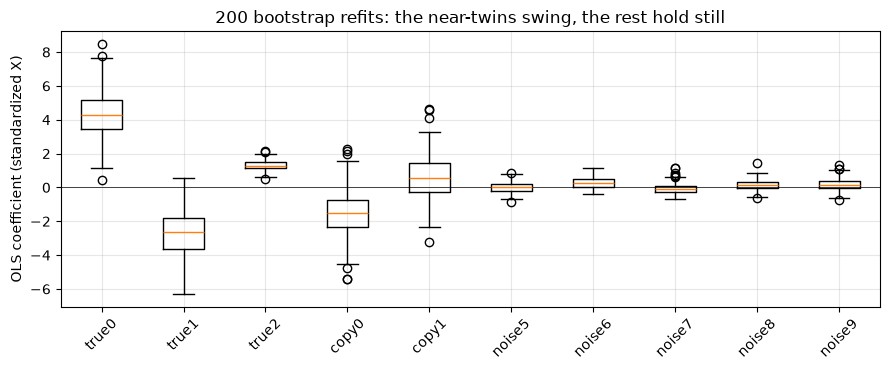

In [8]:
N_BOOT = 200
boot_rng = np.random.default_rng(SEED)
boot_idx = boot_rng.integers(0, len(y_train), size=(N_BOOT, len(y_train)))
PAIRED_IDX, OTHER_IDX = [0, 1, 3, 4], [2, 5, 6, 7, 8, 9]

boot_coefs = np.array([LinearRegression().fit(X_train_s[bi], y_train[bi]).coef_ for bi in boot_idx])
boot_std = np.std(boot_coefs, axis=0)
swing_ratio = (boot_std[PAIRED_IDX].mean() / boot_std[OTHER_IDX].mean())
pair0_sum_std = np.std(boot_coefs[:, 0] + boot_coefs[:, 3])

ols_full = LinearRegression().fit(X_train_s, y_train)
print(pd.DataFrame({"full-data OLS": ols_full.coef_, "bootstrap std": boot_std,
                    "share of resamples < 0": (boot_coefs < 0).mean(axis=0)},
                   index=FEATURES).round(2).to_string())
print(f"\nswing ratio (paired / other): {swing_ratio:.1f}")
print(f"std of true0 + copy0: {pair0_sum_std:.2f}   (true0 alone {boot_std[0]:.2f}, copy0 alone {boot_std[3]:.2f})")

plt.figure(figsize=(9, 3.8))
plt.boxplot(boot_coefs)
plt.axhline(0, color="k", lw=0.5)
plt.xticks(range(1, len(FEATURES) + 1), FEATURES, rotation=45); plt.ylabel("OLS coefficient (standardized X)")
plt.title(f"{N_BOOT} bootstrap refits: the near-twins swing, the rest hold still"); plt.grid(alpha=0.3)
plt.tight_layout(); plt.show()

**Discuss (participation):** the desk's analyst points at the full-data fit: `copy0` gets a
clearly negative weight, though it measures nearly the same thing as `true0`, which pushes
lateness *up*. *"Should we tell the loan officers that copy0 lowers risk?"* Answer the analyst
using your bootstrap — and say what, about the pair, the data *does* pin down.

*We should not tell them that copy0 lowers risk. We see that copy0 flips its sign being positive in 12% of the samples and has a sd of 1.39 which is as big as its coefficient. This means it could just as easily be positive in another sample. It has this large sd because it is correlated with true0 which means the model has a tough time deciding on where to put the weight causing samples with large true0 and small copy0 and vice versa. We could say that combining the 2 features pushes lateness up by 4.25 - 1.43 so about 2.8.*

In [9]:
grader.check("q2")

q2 results: All test cases passed!

## Part 2: which attributes actually matter?

**Why.** Part 1 says the analyst's problem is real: least squares cannot decide how to split
weight between near-twins, and it gives every noise attribute a small weight too. The desk
still wants a short list a loan officer can check — and wants to know whether that list
depends on how hard you penalize. Penalized regression is the way to answer it, and because
this is your simulator you know the right answer (`true0`, `true1`, `true2`) and can grade the
lasso against it. Everything below is fitted on the **standardized** training data until 2c,
which shows what happens if you forget.

### 2a (autograded): coefficient paths for ridge and lasso

The lecture drew the LASSO coefficients against $\log_{10} c$ on the Longley data. Do it here
for both penalties, on the **standardized** training data.

**Task.**

1. `ridge_path`: array of shape `(len(alphas), 10)` — row $k$ is the coefficient vector of
   `Ridge(alpha=alphas[k])` fit on `X_train_s, y_train`.
2. `lasso_path`: same for `Lasso(alpha=alphas[k], max_iter=50000)`.
3. `n_nonzero_lasso`: array of length `len(alphas)` with the number of coefficients whose
   absolute value exceeds `1e-8` at each $\alpha$ (lasso).
4. `ALPHA_REF = 0.5`. Set `selected_at_ref` to the **sorted list of feature indices**
   whose lasso coefficient is nonzero at `alpha=ALPHA_REF` (fit a fresh
   `Lasso(alpha=ALPHA_REF, max_iter=50000)` for it).

Then run the plotting cell and *read* the two paths before moving on.


In [18]:
from sklearn.linear_model import Ridge, Lasso

ALPHA_REF = 0.5

# Uncomment if you want to see the alphas used in the path calculations.
# print("alphas:", np.round(alphas, 3))

# 1. ridge coefficients at each alpha -> shape (len(alphas), 10)
ridge_path = np.array([
    Ridge(alpha=a).fit(X_train_s, y_train).coef_
    for a in alphas
])

# 2. lasso coefficients at each alpha -> shape (len(alphas), 10)
lasso_path = np.array([
    Lasso(alpha=a, max_iter=50000).fit(X_train_s, y_train).coef_
    for a in alphas
])

# 3. number of nonzero lasso coefficients at each alpha (|coef| > 1e-8)
n_nonzero_lasso = (np.abs(lasso_path) > 1e-8).sum(axis=1)

# 4. sorted list of feature indices with nonzero lasso coef at ALPHA_REF
lasso_ref = Lasso(alpha=ALPHA_REF, max_iter=50000).fit(X_train_s, y_train)
selected_at_ref = sorted(np.flatnonzero(np.abs(lasso_ref.coef_) > 1e-8).tolist())

print("lasso: features still nonzero at alpha =", ALPHA_REF, "->", [FEATURES[i] for i in selected_at_ref])
print("number of nonzero lasso coefficients along the path:", n_nonzero_lasso.tolist())


lasso: features still nonzero at alpha = 0.5 -> ['true0', 'true1', 'true2']
number of nonzero lasso coefficients along the path: [10, 10, 10, 9, 9, 9, 8, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 6, 6, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 1, 1, 0, 0, 0, 0, 0, 0, 0]


In [19]:
grader.check("q3")

q3 results: All test cases passed!

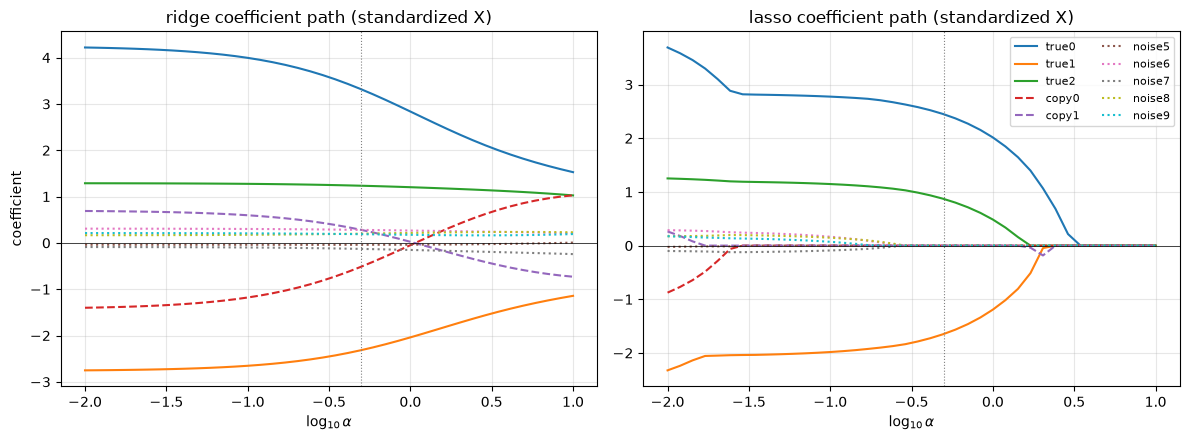

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharex=True)
for ax, path, name in [(axes[0], ridge_path, "ridge"), (axes[1], lasso_path, "lasso")]:
    for j, f in enumerate(FEATURES):
        style = "-" if j in TRUE_IDX else ("--" if j in COPY_IDX else ":")
        ax.plot(np.log10(alphas), path[:, j], style, label=f)
    ax.axhline(0, color="k", lw=0.5)
    ax.axvline(np.log10(ALPHA_REF), color="gray", lw=0.8, ls=":")
    ax.set_xlabel(r"$\log_{10}\alpha$"); ax.set_title(f"{name} coefficient path (standardized X)")
    ax.grid(alpha=0.3)
axes[0].set_ylabel("coefficient")
axes[1].legend(fontsize=8, ncol=2)
plt.tight_layout(); plt.show()


Solid = true features, dashed = their correlated copies, dotted = noise. Ridge shrinks
everything smoothly and never reaches zero; lasso zeroes the noise features first, then a
copy, and eventually the true ones. Notice what it does with a `true`/`copy` pair: it tends
to keep **one** of them and drop the other — with nearly-duplicate columns the choice is close
to arbitrary.


### 2b (autograded): choose $\alpha$ by cross-validation

The lecture set $c$ "by holding out data, i.e. cross-validation". Do exactly that, on the
training set only, then score on the held-out test set.

**Task.**

1. `lasso_cv = LassoCV(alphas=alphas, cv=5, max_iter=50000).fit(X_train_s, y_train)`; 
    1. store the chosen penalty in `alpha_lasso_cv` (a `float`) 
    2. and its test-set MSE in `mse_lasso`.
2. `ridge_cv = RidgeCV(alphas=alphas, cv=5).fit(X_train_s, y_train)`; 
    1. `alpha_ridge_cv`, 
    2. `mse_ridge`.
3. `mse_ols`: test MSE of plain `LinearRegression()` on the same standardized data.
4. `selected_cv`: sorted list of feature indices with nonzero lasso coefficient at `alpha_lasso_cv`
   (read them off `lasso_cv.coef_`).


lasso: alpha_cv = 0.1194   test MSE = 5.457   keeps ['true0', 'true1', 'true2', 'noise6', 'noise7', 'noise8', 'noise9']
ridge: alpha_cv = 1.0000   test MSE = 5.599
OLS  :                    test MSE = 5.482
lasso coefficients at alpha_cv: {'true0': np.float64(2.76), 'true1': np.float64(-1.97), 'true2': np.float64(1.14), 'copy0': np.float64(0.0), 'copy1': np.float64(-0.0), 'noise5': np.float64(-0.0), 'noise6': np.float64(0.14), 'noise7': np.float64(-0.08), 'noise8': np.float64(0.13), 'noise9': np.float64(0.05)}


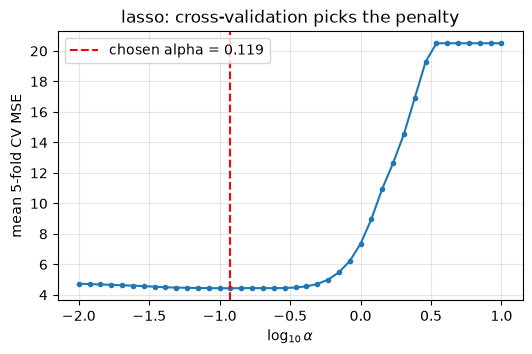

In [21]:
lasso_cv = LassoCV(alphas=alphas, cv=5, max_iter=50000).fit(X_train_s, y_train)
alpha_lasso_cv = lasso_cv.alpha_
mse_lasso = mean_squared_error(y_test, lasso_cv.predict(X_test_s))
ridge_cv =  RidgeCV(alphas=alphas, cv=5).fit(X_train_s, y_train)
alpha_ridge_cv = ridge_cv.alpha_
mse_ridge = mean_squared_error(y_test, ridge_cv.predict(X_test_s))
mse_ols = mean_squared_error(y_test, LinearRegression().fit(X_train_s, y_train).predict(X_test_s))
selected_cv = sorted(np.flatnonzero(np.abs(lasso_cv.coef_) > 1e-8).tolist())

print(f"lasso: alpha_cv = {alpha_lasso_cv:.4f}   test MSE = {mse_lasso:.3f}   keeps {[FEATURES[i] for i in selected_cv]}")
print(f"ridge: alpha_cv = {alpha_ridge_cv:.4f}   test MSE = {mse_ridge:.3f}")
print(f"OLS  :                    test MSE = {mse_ols:.3f}")
print("lasso coefficients at alpha_cv:", dict(zip(FEATURES, np.round(lasso_cv.coef_, 2))))

# CV curve: mean held-out MSE per alpha (LassoCV stores it, alphas descending)
plt.figure(figsize=(6, 3.5))
plt.plot(np.log10(lasso_cv.alphas_), lasso_cv.mse_path_.mean(axis=1), "o-", ms=3)
plt.axvline(np.log10(alpha_lasso_cv), color="red", ls="--", label=f"chosen alpha = {alpha_lasso_cv:.3f}")
plt.xlabel(r"$\log_{10}\alpha$"); plt.ylabel("mean 5-fold CV MSE"); plt.legend(); plt.grid(alpha=0.3)
plt.title("lasso: cross-validation picks the penalty"); plt.show()


**Discuss (participation):** the desk wants a short list of attributes a loan officer can
check by hand. At `ALPHA_REF = 0.5` the lasso handed you exactly the three that matter; at the
CV-chosen $\alpha$ it keeps several noise attributes with small coefficients, and predicts a
little better. Which list do you give the desk, and what was cross-validation optimizing that
the desk did not ask for?

*Give the desk the ALPHA_REF = 0.5 list: true0, true1, true2. Cross-validation was optimizing out-of-sample prediction error (mean 5-fold CV MSE), not a short, hand-checkable list: at α ≈ 0.119 it happily keeps noise attributes (noise6-9) because their small coefficients shave a little off the prediction error, which is why the CV-chosen model's test MSE (5.457) is only marginally better than the sparser alternative and OLS (5.482).

If you want a line on why this is safe to do: the CV curve is nearly flat between log₁₀α ≈ -1.5 and -0.5, so the extra accuracy from the noise features is within what the data can distinguish, and you lose essentially nothing by choosing the sparser, more interpretable list.

One caveat worth keeping in mind: that the lasso keeps true0 and drops copy0 is partly arbitrary given they're near-twins (the same identifiability issue as in the bootstrap), so the desk should read "true0" as standing for the pair's combined signal.*


In [22]:
grader.check("q4")

q4 results: All test cases passed!

### 2c (autograded): what if you forget to standardize?

Fit the lasso at the **same** `alpha_lasso_cv` on the raw, unstandardized `X_train` — the
columns whose standard deviations you printed above range from ~0.005 to ~50.

**Task.**

1. `lasso_raw = Lasso(alpha=alpha_lasso_cv, max_iter=50000).fit(X_train, y_train)`.
2. `selected_raw`: sorted list of feature indices with nonzero coefficient.
3. `mse_raw`: its test MSE on `X_test`.
4. `dropped_true_raw`: sorted list of indices in `TRUE_IDX` that the raw fit set to zero.


In [23]:
lasso_raw = Lasso(alpha=alpha_lasso_cv, max_iter=50000).fit(X_train, y_train)
selected_raw = sorted(np.flatnonzero(np.abs(lasso_raw.coef_) > 1e-8).tolist())
mse_raw = mean_squared_error(y_test, lasso_raw.predict(X_test))
dropped_true_raw = sorted(set(TRUE_IDX) - set(selected_raw))

print("raw lasso coefficients:", dict(zip(FEATURES, np.round(lasso_raw.coef_, 3))))
print(f"raw:          keeps {[FEATURES[i] for i in selected_raw]}, drops true {[FEATURES[i] for i in dropped_true_raw]}, test MSE = {mse_raw:.3f}")
print(f"standardized: keeps {[FEATURES[i] for i in selected_cv]}, test MSE = {mse_lasso:.3f}")


raw lasso coefficients: {'true0': np.float64(2.347), 'true1': np.float64(-1.897), 'true2': np.float64(0.0), 'copy0': np.float64(0.44), 'copy1': np.float64(-0.0), 'noise5': np.float64(0.012), 'noise6': np.float64(0.14), 'noise7': np.float64(-0.008), 'noise8': np.float64(0.227), 'noise9': np.float64(0.057)}
raw:          keeps ['true0', 'true1', 'copy0', 'noise5', 'noise6', 'noise7', 'noise8', 'noise9'], drops true ['true2'], test MSE = 8.928
standardized: keeps ['true0', 'true1', 'true2', 'noise6', 'noise7', 'noise8', 'noise9'], test MSE = 5.457


**Discuss (participation):** the desk's warehouse stores `true2` in tiny units (think a ratio
kept as a fraction where every other column is in dollars or years), and your unstandardized
fit threw it out even though it genuinely drives the outcome. Explain to the desk's data
engineer, using the penalty term, why the *units* a column is stored in decided whether the
lasso kept it — and what you need to do before you refit. Which lecture slide warned you about
this?

*(1-2 sentences here)*


In [24]:
grader.check("q5")

q5 results: All test cases passed!

## Part 3: the short list for a yes/no outcome

**Why.** The desk approves or declines; what it really wants to know is which attributes
predict *whether a loan is repaid*. Monday's model for a yes/no outcome was logistic
regression, and the lasso's L1 penalty works there too: `LogisticRegression(penalty="l1")`
zeroes coefficients exactly as `Lasso` did.

One trap in the API. `LogisticRegression` does not take $\alpha$; it takes **`C`, the inverse
of the penalty strength**. **Smaller `C` means more penalty and fewer attributes**; larger `C`
means less penalty. (It also applies an L2 penalty by default, which is why Monday's code said
`penalty=None`.) The L1 penalty needs a solver that supports it: `liblinear` or `saga`.

`y_train_bin` (provided) is **1 = repaid on or ahead of schedule** (`y_train <= 0`), 0 = ran
behind.

### 3 (autograded): L1-penalized logistic regression

**Task.** On `X_train_s`, `y_train_bin`:

1. `n_kept_C` — an integer array of length `len(Cs)`: the number of coefficients with absolute
   value above `1e-8` in `LogisticRegression(penalty="l1", solver="liblinear", C=C)` at each
   `C` in `Cs`.
2. `l1_logit` — the same model fitted at `C = C_REF`, and `kept_l1` — the **sorted list** of
   feature indices whose coefficient is nonzero in it.

In [ ]:
y_train_bin = (y_train <= 0).astype(int)
Cs = np.logspace(-2, 1, 30)
C_REF = 0.3

# Calculate n_kept_C
...

l1_logit = ...
kept_l1 = ...


print(f"{y_train_bin.mean():.0%} of training loans repaid on or ahead of schedule")
print(f"L1 logistic at C = {C_REF}: keeps {[FEATURES[i] for i in kept_l1]}")
print(f"lasso at alpha = {ALPHA_REF} (2a): keeps {[FEATURES[i] for i in selected_at_ref]}")
plt.figure(figsize=(6, 3.5))
plt.step(np.log10(Cs), n_kept_C, where="mid")
plt.axvline(np.log10(C_REF), color="gray", ls=":", label=f"C_REF = {C_REF}")
plt.xlabel(r"$\log_{10} C$  (left = more penalty)"); plt.ylabel("attributes kept")
plt.legend(); plt.grid(alpha=0.3); plt.title("L1 logistic: smaller C, shorter list"); plt.show()

In [ ]:
grader.check("q6")

<!-- BEGIN QUESTION -->

## Report out: what you would tell the lending desk

Write the two sentences you would put at the top of your memo to the lending desk: the
**recommendation** — the short list of attributes the loan officers should check — and the
**one caveat** they must hear. Then pair-share with another team.

Use your numbers:

- Which attributes go on the list, and which method and penalty produced it? Did the lasso at
  `ALPHA_REF`, the CV-chosen lasso and the L1 logistic regression of Part 3 agree — and if not,
  which list fits the desk's request?
- `true0` and `copy0` measure nearly the same thing. When the lasso keeps one and drops the
  other, what does that say about the one it dropped — and would it pick the same one next
  quarter (Part 1)?
- What did the analyst do wrong by reading weights off plain least squares, and what must
  happen before any penalized fit (2c)?

Write the memo in the answer cell below — your team members' names, then **Recommendation:**
and **Caveat:** — and cite numbers from your notebook (`swing_ratio`, `selected_at_ref`,
`selected_cv`, `kept_l1`, the paths) where they support a claim.

**Pair-share (~3 min).** Compare memos with a neighboring team: same list? Same caveat?
Be ready to share one takeaway with the class.

> Staff will visit tables during this part. Be ready to explain your reasoning and to
> point at the cell that supports each claim.

_Type your answer here, replacing this text._

<!-- END QUESTION -->

## Wrap-up

Before you leave, each group should be able to answer, without notes:

1. What did the condition number and the bootstrap each tell you about the desk's attributes,
   and which of them answers the analyst's complaint directly?
2. What did the lasso do to the noise attributes that ridge never did, and why did it drop
   `true2` when you forgot to standardize?
3. In `LogisticRegression`, which way do you turn `C` to get a shorter list, and what does the
   lasso do with a pair of near-twin attributes?

Submit the autograded parts (1a–3) to Gradescope.